In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
from scipy.stats import mannwhitneyu, skew
import warnings
warnings.filterwarnings('ignore')

##### Enriched data with paid/unpaid policies with also the source of business purchase. This data will help us sort of, form a time series analysis to see more clearly sales on each day/ month i.e., the users' interaction with the platfrom.



In [34]:
low_freq = pd.read_excel('droppers2.xlsx', sheet_name= 'Low-freq buyers (enriched)')

low_freq = low_freq.rename(columns= {'o ': 'products_viewed'})

low_freq.head()


,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,unpaid_policies,pwa_sales,old_platform_sales,last_sale_date
0,15,42,1,15.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,254712129778,1,2,0,2026-10-08
1,10,24,1,10.0,13,44,Caroline Gakii,Nairobi City,cgkinoti@gmail.com,254720939955,5,13,0,2026-10-09
2,10,22,1,10.0,218,232,Simon Mwandima,Nairobi City,nadimainsurance@gmail.com,254722518214,1,20,198,2026-10-02
3,9,28,1,9.0,4,13,Dennis Mwendwa,Nairobi City,dmwendwamutuku@gmail.com,254708506341,0,4,0,2026-10-05
4,9,41,1,9.0,150,144,CRESTPOINT INSURANCE AGENCY,Nairobi City,crestpointinsuranceagency@gmail.com,254727324505,1,20,130,2026-10-09


In [35]:
droppers = pd.read_excel('droppers2.xlsx', sheet_name= 'Droppers (no sales since Sep30)')

droppers.head()

,products_viewed,view_events,sales_before_tracking,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,unpaid_policies,pwa_sales,old_platform_sales,last_sale_date
0,14,32,3,3,4,Eastman Magembe,NaN,emagembe2019@gmail.com,254705440772,0,1,2,2026-08-05
1,10,24,111,111,127,ENOS LICHA,Nairobi City,enoslicha224@gmail.com,254720489337,3,45,66,2026-09-29
2,9,21,103,103,101,James Muoki,Nairobi City,jmuoki88@gmail.com,254714831970,4,75,28,2026-09-24
3,8,26,35,35,52,Jackson Ngigi Mburu,Kiambu,jacksonngigi1@gmail.com,254703258044,0,19,16,2026-09-14
4,7,20,23,23,52,Joy Muthoni,Nairobi City,joycemuthoni422@gmail.com,254722567508,4,16,7,2026-09-28


In [36]:
print(low_freq.columns)

print(droppers.columns)

Index(['products_viewed', 'view_events', 'sales_since_sep30',
       'viewed_per_sale', 'all_sales_alltime', 'quotes_alltime', 'user_name',
       'county', 'email', 'phone_number', 'unpaid_policies', 'pwa_sales',
       'old_platform_sales', 'last_sale_date'],
      dtype='object')
Index(['products_viewed', 'view_events', 'sales_before_tracking',
       'all_sales_alltime', 'quotes_alltime', 'user_name', 'county', 'email',
       'phone_number', 'unpaid_policies', 'pwa_sales', 'old_platform_sales',
       'last_sale_date'],
      dtype='object')


In [37]:
#We drop sales before tracking for the droppers column since it has the same sale numbers as sales all time as sales_before_tracking = all_sales_alltime − 0 = all_sales_alltime

# Should print True for every row
print((droppers["sales_before_tracking"] == droppers["all_sales_alltime"]).all())

droppers = droppers.drop(columns=["sales_before_tracking"])

True


In [38]:
print(low_freq.info())



print(droppers.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 578 entries, 0 to 577
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   products_viewed     578 non-null    int64         
 1   view_events         578 non-null    int64         
 2   sales_since_sep30   578 non-null    int64         
 3   viewed_per_sale     578 non-null    float64       
 4   all_sales_alltime   578 non-null    int64         
 5   quotes_alltime      578 non-null    int64         
 6   user_name           578 non-null    object        
 7   county              575 non-null    object        
 8   email               578 non-null    object        
 9   phone_number        578 non-null    int64         
 10  unpaid_policies     578 non-null    int64         
 11  pwa_sales           578 non-null    int64         
 12  old_platform_sales  578 non-null    int64         
 13  last_sale_date      578 non-null    datetime64[ns]

Combine the two dataframes

In [39]:
# Columns unique to each dataframe
print("Only in low_freq:")
print(sorted(set(low_freq.columns) - set(droppers.columns)))

print("\nOnly in droppers:")
print(sorted(set(droppers.columns) - set(low_freq.columns)))

print("\nColumns shared by both:")
print(sorted(set(low_freq.columns) & set(droppers.columns)))

Only in low_freq:
['sales_since_sep30', 'viewed_per_sale']

Only in droppers:
[]

Columns shared by both:
['all_sales_alltime', 'county', 'email', 'last_sale_date', 'old_platform_sales', 'phone_number', 'products_viewed', 'pwa_sales', 'quotes_alltime', 'unpaid_policies', 'user_name', 'view_events']


In [40]:

# Make copies so the original dataframes remain unchanged
low_freq_copy = low_freq.copy()
droppers_copy = droppers.copy()

# Create the target label
low_freq_copy['is_dropper'] = 0
droppers_copy['is_dropper'] = 1

# Combine both datasets
combined = pd.concat(
    [low_freq_copy, droppers_copy],
    ignore_index=True,
    sort=False
)

# Check the result
print(combined.shape)
print(combined['is_dropper'].value_counts())
combined

(768, 15)
is_dropper
0    578
1    190
Name: count, dtype: int64


,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,unpaid_policies,pwa_sales,old_platform_sales,last_sale_date,is_dropper
0,15,42,1.0,15.0,2,7,Kevin Ng'ang'a,Nairobi City,nyoikekelvin@gmail.com,254712129778,1,2,0,2026-10-08,0
1,10,24,1.0,10.0,13,44,Caroline Gakii,Nairobi City,cgkinoti@gmail.com,254720939955,5,13,0,2026-10-09,0
2,10,22,1.0,10.0,218,232,Simon Mwandima,Nairobi City,nadimainsurance@gmail.com,254722518214,1,20,198,2026-10-02,0
3,9,28,1.0,9.0,4,13,Dennis Mwendwa,Nairobi City,dmwendwamutuku@gmail.com,254708506341,0,4,0,2026-10-05,0
4,9,41,1.0,9.0,150,144,CRESTPOINT INSURANCE AGENCY,Nairobi City,crestpointinsuranceagency@gmail.com,254727324505,1,20,130,2026-10-09,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,1,2,NaN,NaN,10,13,COMPLIANCE INSURANCE AGENCIES,Mombasa,karisakironda@gmail.com,254115912360,0,10,0,2026-07-22,1
764,1,2,NaN,NaN,48,55,MARTIN NJICHA KARUGI,Nairobi City,martinkarugi36@gmail.com,254795389476,4,0,48,2026-09-24,1
765,1,2,NaN,NaN,0,0,JOB KASEMBELI,Trans Nzoia,jobnasongo@gmail.com,254725144800,0,0,0,NaT,1
766,1,2,NaN,NaN,1,9,Lydia Maina,Nairobi City,lydiawairimu475@gmail.com,254757171824,0,1,0,2026-09-26,1


1 = the agent is in droppers ~ a dropper



0 = the agent is in low_freq ~ a low frequency buyer

In [41]:
combined.columns

Index(['products_viewed', 'view_events', 'sales_since_sep30',
       'viewed_per_sale', 'all_sales_alltime', 'quotes_alltime', 'user_name',
       'county', 'email', 'phone_number', 'unpaid_policies', 'pwa_sales',
       'old_platform_sales', 'last_sale_date', 'is_dropper'],
      dtype='object')

#### Compare droppers with active agents

In [42]:
# Create a copy
cmb = combined.copy()


In [43]:
cmb = cmb[ -cmb['user_name'].isin(['zarko maksovic test', 'Mary Kithuku', 'Elisha Njoga'])]

In [44]:
#Droppers have no sales since sep 30 value after merge with low freq;

cmb['sales_since_sep30'] = cmb['sales_since_sep30'].fillna(0)

In [45]:
cmb['last_sale_date']= pd.to_datetime(cmb['last_sale_date'])

SNAPSHOT = pd.Timestamp('2026-10-12')  #date of enriched 

cmb['group'] = np.where(cmb['is_dropper']==1, 'Dropper', 'Active')

#days since last sale; empty (nan) for agents who have never sold
cmb['days_since_last_sale'] = (SNAPSHOT - cmb['last_sale_date']).dt.days

# % of lifetime sales made on PWA
total_platform = cmb['pwa_sales'] + cmb['old_platform_sales']

cmb['pwa_share'] = np.where(total_platform > 0, cmb['pwa_sales']/ total_platform * 100, np.nan)

#unpaid policies per 100 lifetime sales
cmb['unpaid_per_100_sales'] = np.where(cmb['all_sales_alltime']>0,
                                       cmb['unpaid_policies']/ cmb['all_sales_alltime'] * 100, np.nan)

#lifetime sales per 100 quotes

cmb['sales_per_100_quotes'] = np.where(cmb['quotes_alltime']>0, 
                                      cmb['all_sales_alltime']/ cmb['quotes_alltime'] * 100, np.nan)



In [46]:
print(cmb['group'].value_counts())

group
Active     578
Dropper    187
Name: count, dtype: int64


Run a Mann-Whitney test to test if there is a  statistical significant difference between the two groups in the way they interact with the platform. This is in terms of browsing activity and the sale purchases

In [47]:
# summary table - typical (median) agent in each group
# p_value: Mann-Whitney test; below 0.05 means the two groups really differ
# ---------------------------------------------------------------
metrics = {
    "view_events": "View events",
    "products_viewed": "Products viewed",
    "quotes_alltime": "Lifetime quotes",
    "all_sales_alltime": "Lifetime sales",
    "sales_per_100_quotes": "Sales per 100 quotes",
    "pwa_share": "% of sales on PWA",
    "unpaid_policies": "Unpaid policies",
    "unpaid_per_100_sales": "Unpaid per 100 sales",
    "days_since_last_sale": "Days since last sale",
}


rows = []
for col, label in metrics.items():
    drop = cmb.loc[cmb["group"] == "Dropper", col].dropna()
    act = cmb.loc[cmb["group"] == "Active", col].dropna()
    p = mannwhitneyu(drop, act).pvalue
    rows.append([label, drop.median(), act.median(), p])
summary = pd.DataFrame(rows, columns=["metric", "dropper_median", "active_median", "p_value"])
print("\n", summary.round(3).to_string(index=False))


               metric  dropper_median  active_median  p_value
         View events           2.000         10.000    0.000
     Products viewed           1.000          3.000    0.000
     Lifetime quotes          14.000        152.500    0.000
      Lifetime sales           9.000        159.000    0.000
Sales per 100 quotes          77.098         98.240    0.000
   % of sales on PWA          52.406         33.060    0.042
     Unpaid policies           0.000          2.000    0.000
Unpaid per 100 sales           0.000          0.979    0.010
Days since last sale          28.000          3.000    0.000


### Comparison of Dropper and Active Agents

The Mann–Whitney U tests identified statistically significant distributional differences between Dropper and Active agents across all nine metrics tested (unadjusted p-values). Dropper agents had substantially lower median browsing activity, lifetime quotes and lifetime sales. They also had a longer median time since their last sale (28 days versus 3 days), making sales recency a potentially useful indicator for prioritising agent follow-up.

Despite their lower business volumes, droppers had a higher median sales-to-quotes ratio and a greater share of recorded sales on the PWA. These findings require further validation to determine whether they reflect genuine differences in conversion behaviour or differences in metric definitions, denominators and platform migration history. Active agents also had higher median unpaid-policy counts and rates.

Overall, the findings suggest that reduced browsing activity, low historical business volume and longer periods without a sale can help distinguish the two groups. However, these associations do not establish that low browsing causes lower sales. Further analysis of changes in each agent's sales over time is needed to identify genuine business decline and distinguish it from historically low-volume agents.

Because of the inconsistencies of the results, we will visualize the distribution of both groups before interpreting the Mann Whitney results and focus the prediction analysis on activity after September 30, when PWA product-view tracking began, rather than relying on historical sales as predictive features.

Historical sales can still be useful for understanding the groups, but excluding them from the predictive features helps us avoid letting long-term sales volume dominate a model intended to detect recent changes.

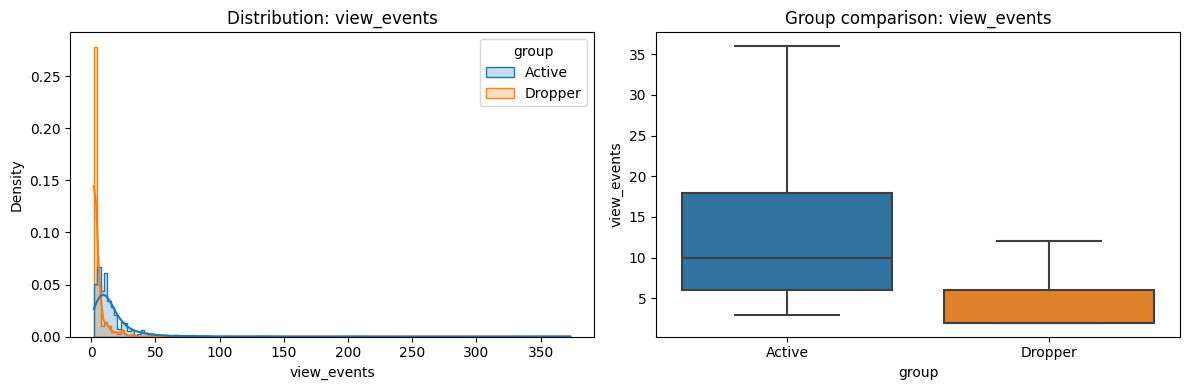


view_events
Active: n=578, median=10.00, skewness=8.64
Dropper: n=187, median=2.00, skewness=2.75


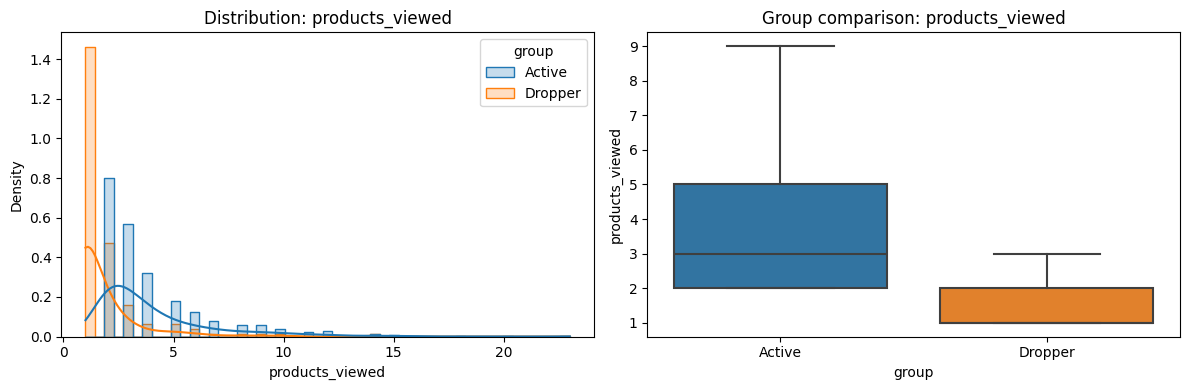


products_viewed
Active: n=578, median=3.00, skewness=2.40
Dropper: n=187, median=1.00, skewness=3.59


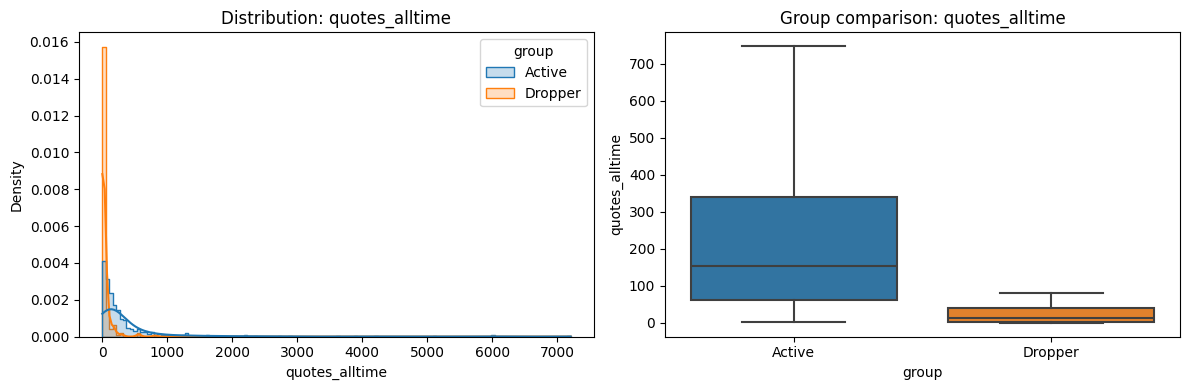


quotes_alltime
Active: n=578, median=152.50, skewness=5.75
Dropper: n=187, median=14.00, skewness=5.29


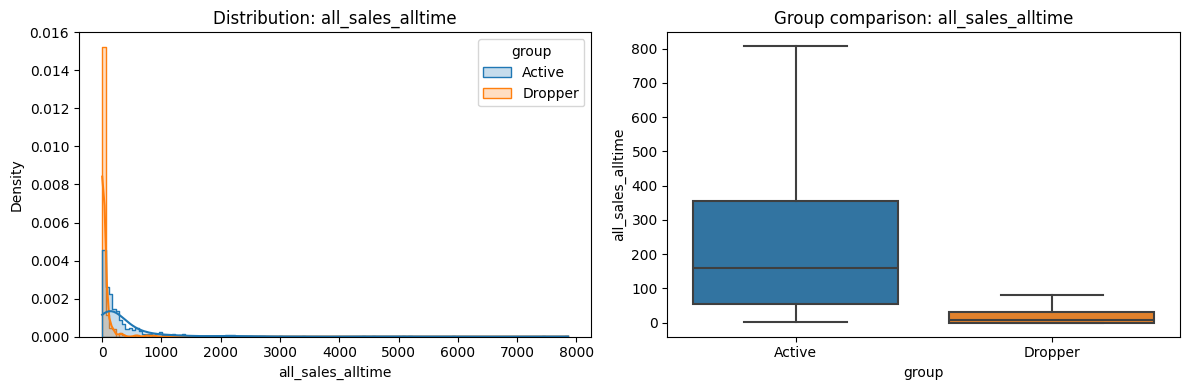


all_sales_alltime
Active: n=578, median=159.00, skewness=5.71
Dropper: n=187, median=9.00, skewness=5.45


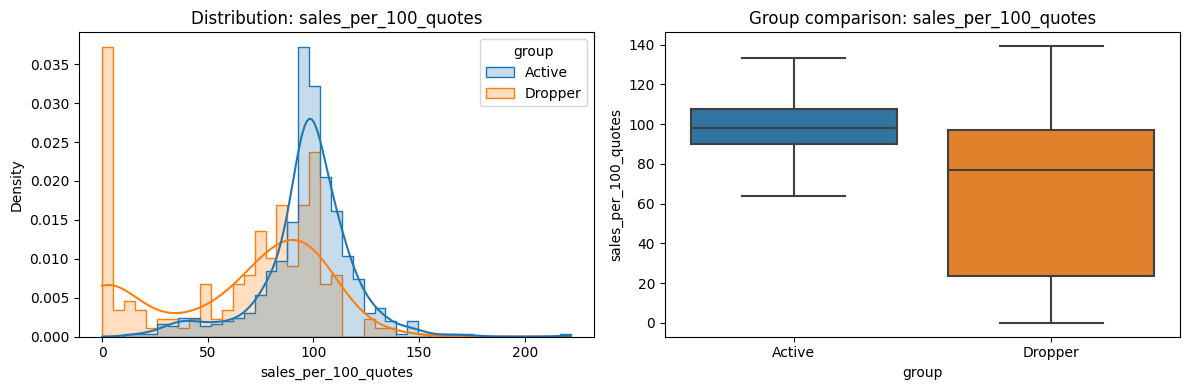


sales_per_100_quotes
Active: n=578, median=98.24, skewness=-0.41
Dropper: n=172, median=77.10, skewness=-0.54


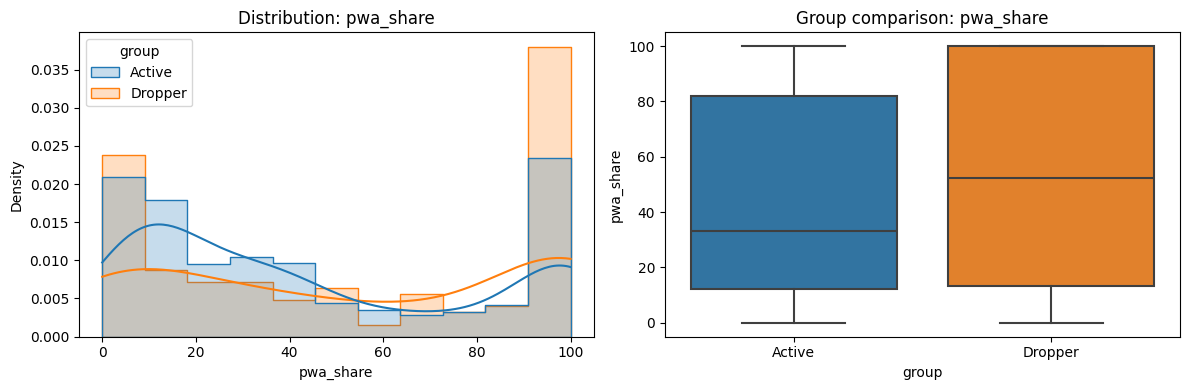


pwa_share
Active: n=578, median=33.06, skewness=0.51
Dropper: n=139, median=52.41, skewness=-0.05


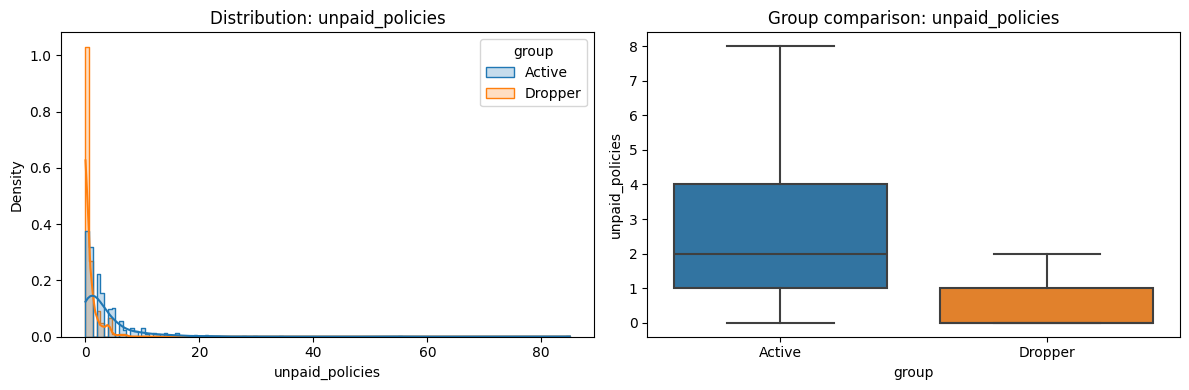


unpaid_policies
Active: n=578, median=2.00, skewness=6.84
Dropper: n=187, median=0.00, skewness=2.40


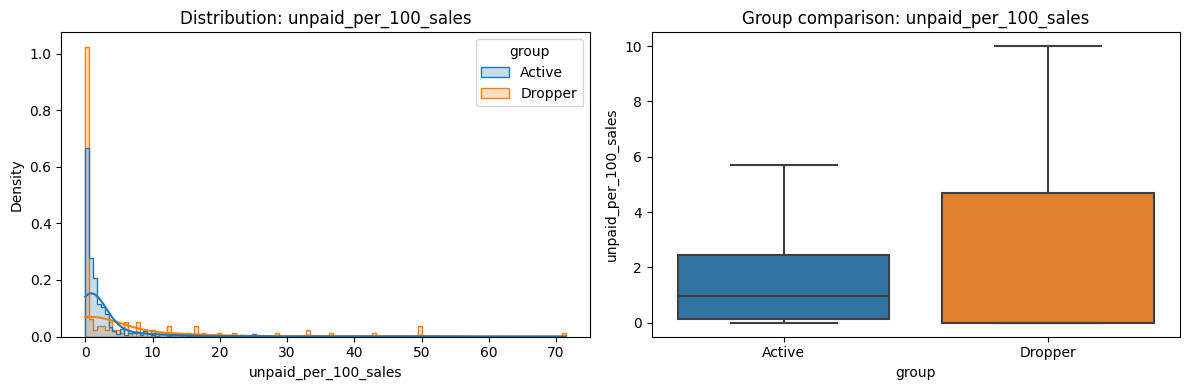


unpaid_per_100_sales
Active: n=578, median=0.98, skewness=5.35
Dropper: n=139, median=0.00, skewness=3.20


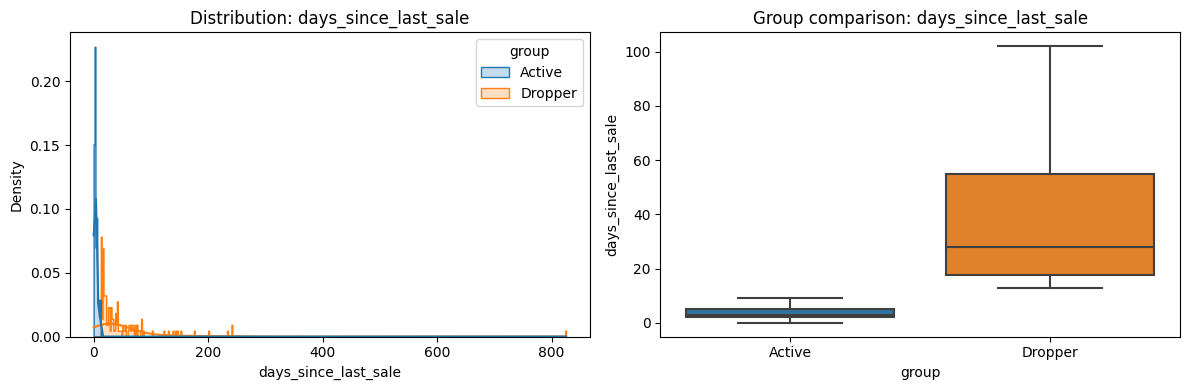


days_since_last_sale
Active: n=578, median=3.00, skewness=1.10
Dropper: n=139, median=28.00, skewness=6.98


In [48]:
#Check the distribution shapes of both groups,The medians and p-values are useful, but the sales and browsing variables are likely to be right-skewed, with many agents having low counts and a few agents having very high counts. Verify that rather than assume it.


metrics_to_check = [
    "view_events",
    "products_viewed",
    "quotes_alltime",
    "all_sales_alltime",
    "sales_per_100_quotes",
    "pwa_share",
    "unpaid_policies",
    "unpaid_per_100_sales",
    "days_since_last_sale"
]

# Compare the distributions for each metric
for col in metrics_to_check:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=cmb, x=col, hue="group",
        element="step", stat="density",
        common_norm=False, kde=True, ax=axes[0]
    )
    axes[0].set_title(f"Distribution: {col}")

    sns.boxplot(
        data=cmb, x="group", y=col,
        showfliers=False, ax=axes[1]
    )
    axes[1].set_title(f"Group comparison: {col}")

    plt.tight_layout()
    plt.show()

    print(f"\n{col}")
    for group_name, subset in cmb.groupby("group"):
        values = subset[col].dropna()
        print(
            f"{group_name}: n={len(values)}, "
            f"median={values.median():.2f}, "
            f"skewness={skew(values):.2f}"
        )


### Test the post September 30th activity,, YAAAAYYYY!!! my favorite part

In [49]:
combined.columns

Index(['products_viewed', 'view_events', 'sales_since_sep30',
       'viewed_per_sale', 'all_sales_alltime', 'quotes_alltime', 'user_name',
       'county', 'email', 'phone_number', 'unpaid_policies', 'pwa_sales',
       'old_platform_sales', 'last_sale_date', 'is_dropper'],
      dtype='object')

In [50]:
# Tests on post-Sep 30 activity and last_sale_date
# Uses your `combined` frame. Columns read:
#   sales_since_sep30, all_sales_alltime, last_sale_date, products_viewed,
#   viewed_per_sale, view_events, user_name, is_dropper
# `combined` is not changed: the tests run on a copy called `chk`.

from scipy.stats import spearmanr

chk = combined.copy()
chk["sales_since_sep30"] = chk["sales_since_sep30"].fillna(0)   # empty for droppers after the merge = 0
chk["last_sale_date"] = pd.to_datetime(chk["last_sale_date"])

SEP30 = pd.Timestamp("2026-09-30")      # start of the window
SNAPSHOT = pd.Timestamp("2026-10-12")   # date of the enriched sheet
active = chk[chk["is_dropper"] == 0]
drop = chk[chk["is_dropper"] == 1]

# Each test: (description, number of rows that FAIL it). 0 failures = pass.
tests = [
    ("Active agents have at least 1 sale since Sep 30",
     (active["sales_since_sep30"] < 1).sum()),
    ("Active agents' last sale is on or after Sep 30",
     (active["last_sale_date"] < SEP30).sum()),
    ("Active agents all have a last_sale_date",
     active["last_sale_date"].isna().sum()),
    ("Droppers' last sale is before Sep 30 (or they never sold)",
     (drop["last_sale_date"] >= SEP30).sum()),
    ("Droppers with no last_sale_date have 0 lifetime sales",
     (drop["last_sale_date"].isna() & (drop["all_sales_alltime"] > 0)).sum()),
    ("Droppers with 0 lifetime sales have no last_sale_date",
     (drop["last_sale_date"].notna() & (drop["all_sales_alltime"] == 0)).sum()),
    ("No last_sale_date after the snapshot (Oct 12)",
     (chk["last_sale_date"] > SNAPSHOT).sum()),
    ("sales_since_sep30 is not more than all_sales_alltime",
     (chk["sales_since_sep30"] > chk["all_sales_alltime"]).sum()),
    # Compared unrounded, allowing 0.05: the sheet rounds halves up (1.25 -> 1.3), Python does not
    ("viewed_per_sale = products_viewed / sales_since_sep30 (to 1 decimal)",
     (abs(active["products_viewed"] / active["sales_since_sep30"]
          - active["viewed_per_sale"]) > 0.0501).sum()),
]
results = pd.DataFrame(tests, columns=["test", "rows_failing"])
results["result"] = np.where(results["rows_failing"] == 0, "PASS", "CHECK")
print(results.to_string(index=False))

# ---------------------------------------------------------------
# Post-Sep 30 activity: when did active agents last sell?
# NEW COLUMN on the copy: days_since_last_sale = Oct 12 - last_sale_date
# ---------------------------------------------------------------
chk["days_since_last_sale"] = (SNAPSHOT - chk["last_sale_date"]).dt.days
active = chk[chk["is_dropper"] == 0]
drop = chk[chk["is_dropper"] == 1]

print("\nActive agents by last sale date:")
print(active["last_sale_date"].dt.date.value_counts().sort_index())
print("Policies since Sep 30 (active agents):", int(active["sales_since_sep30"].sum()))

# Does selling more go with a more recent last sale? (active agents)
r, p = spearmanr(active["sales_since_sep30"], active["days_since_last_sale"])
print(f"\nActive: sales since Sep 30 vs days since last sale: rho={r:.2f}, p={p:.3g}")

# Do droppers who browse more have a more recent last sale?
d = drop.dropna(subset=["days_since_last_sale"])
r, p = spearmanr(d["view_events"], d["days_since_last_sale"])
print(f"Droppers: view events vs days since last sale: rho={r:.2f}, p={p:.3g} (n={len(d)})")

print("\nDroppers' last sale by month:")
print(drop["last_sale_date"].dt.to_period("M").value_counts().sort_index())
print("Never sold:", drop["last_sale_date"].isna().sum())

# ---------------------------------------------------------------
# OPTIONAL: compare with the Oct 8 sheet.
# Load its Low-freq buyers tab as `low_freq_oct8` first, e.g.
#   low_freq_oct8 = pd.read_excel("LAMI_droppers_oct8.xlsx", sheet_name=1)
# Rules: a count can only go up; if it went up, the last sale must be on/after Oct 8;
# if it stayed the same, the last sale must be on/before Oct 8.
# ---------------------------------------------------------------
if "low_freq_oct8" in globals():
    OCT8 = pd.Timestamp("2026-10-08")
    key = lambda s: s.str.lower().str.strip()
    m = (low_freq_oct8.assign(k=key(low_freq_oct8["email"]))[["k", "sales_since_sep30"]]
         .merge(active.assign(k=key(active["email"]))[["k", "user_name", "sales_since_sep30", "last_sale_date"]],
                on="k", suffixes=("_oct8", "_oct12")))
    rose = m["sales_since_sep30_oct12"] > m["sales_since_sep30_oct8"]
    same = m["sales_since_sep30_oct12"] == m["sales_since_sep30_oct8"]
    print("\nOct 8 agents matched:", len(m))
    print("Count fell (should be 0):", (m["sales_since_sep30_oct12"] < m["sales_since_sep30_oct8"]).sum())
    print("Rose but last sale before Oct 8 (should be 0):", (rose & (m["last_sale_date"] < OCT8)).sum())
    print("Unchanged but last sale after Oct 8 (should be 0):", (same & (m["last_sale_date"] > OCT8)).sum())

                                                                test  rows_failing result
                     Active agents have at least 1 sale since Sep 30             0   PASS
                      Active agents' last sale is on or after Sep 30             0   PASS
                             Active agents all have a last_sale_date             0   PASS
           Droppers' last sale is before Sep 30 (or they never sold)             0   PASS
               Droppers with no last_sale_date have 0 lifetime sales             0   PASS
               Droppers with 0 lifetime sales have no last_sale_date             0   PASS
                       No last_sale_date after the snapshot (Oct 12)             0   PASS
                sales_since_sep30 is not more than all_sales_alltime             0   PASS
viewed_per_sale = products_viewed / sales_since_sep30 (to 1 decimal)             0   PASS

Active agents by last sale date:
last_sale_date
2026-09-30     11
2026-10-01     15
2026-10-02     

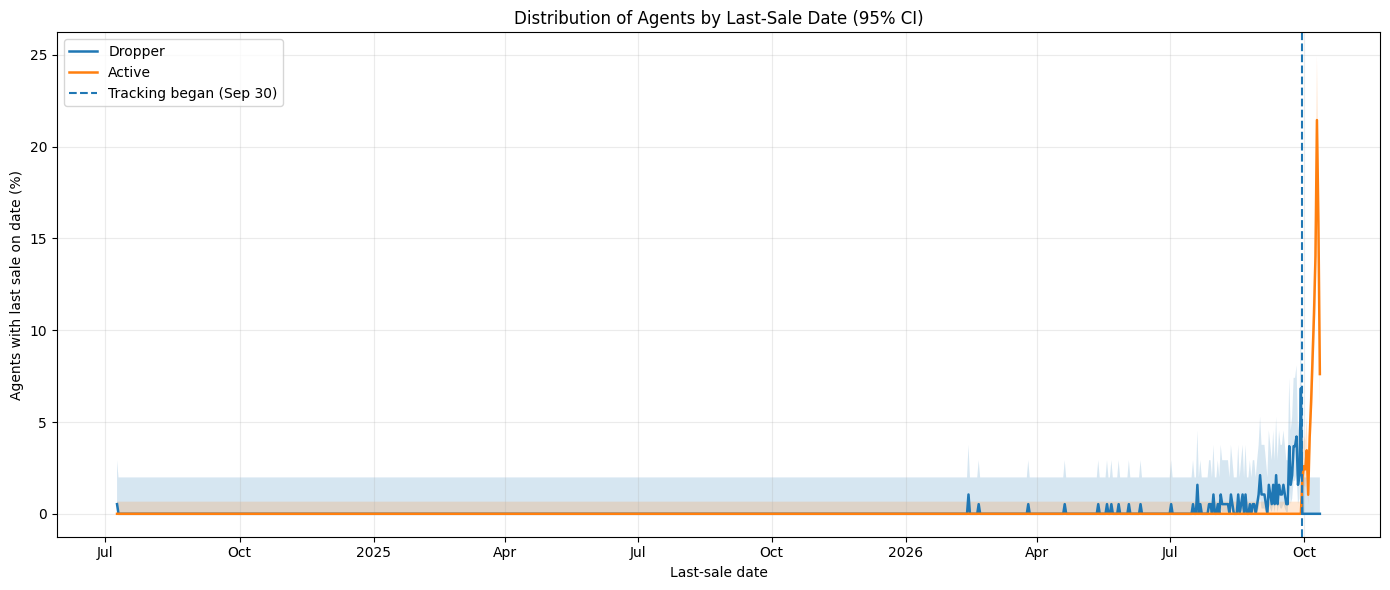

Agents per group:
group
Active     578
Dropper    190
Name: count, dtype: int64

Agents with no recorded last-sale date:
group
Dropper    48
Name: count, dtype: int64


In [51]:


import matplotlib.dates as mdates
from statsmodels.stats.proportion import proportion_confint

chk = combined.copy()

chk["last_sale_date"] = pd.to_datetime(
    chk["last_sale_date"], errors="coerce"
)

chk["group"] = np.where(
    chk["is_dropper"].eq(1), "Dropper", "Active"
)

SNAPSHOT = pd.Timestamp("2026-10-12")
SEP30 = pd.Timestamp("2026-09-30")

# Date range for all recorded last-sale dates
start = chk["last_sale_date"].min().normalize()
dates = pd.date_range(start, SNAPSHOT, freq="D")

rows = []

for group in ["Dropper", "Active"]:
    subset = chk[chk["group"] == group]
    n = len(subset)

    # Number of agents whose last sale was on each date
    counts = (
        subset["last_sale_date"]
        .dt.normalize()
        .value_counts()
    )

    for date in dates:
        count = int(counts.get(date, 0))
        proportion = count / n if n else np.nan

        # 95% Wilson confidence interval for the proportion
        if n:
            lower, upper = proportion_confint(
                count, n, alpha=0.05, method="wilson"
            )
        else:
            lower, upper = np.nan, np.nan

        rows.append({
            "group": group,
            "date": date,
            "count": count,
            "percentage": proportion * 100,
            "lower": lower * 100,
            "upper": upper * 100
        })

daily = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(14, 6))

for group in ["Dropper", "Active"]:
    g = daily[daily["group"] == group].sort_values("date")

    ax.plot(
        g["date"], g["percentage"],
        label=group, linewidth=1.8
    )

    ax.fill_between(
        g["date"], g["lower"], g["upper"],
        alpha=0.18
    )

# Mark the beginning of PWA product-view tracking
ax.axvline(
    SEP30, linestyle="--", linewidth=1.5,
    label="Tracking began (Sep 30)"
)

ax.set_title(
    "Distribution of Agents by Last-Sale Date (95% CI)"
)
ax.set_xlabel("Last-sale date")
ax.set_ylabel("Agents with last sale on date (%)")
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(ax.xaxis.get_major_locator())
)

ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()

plt.savefig(
    "last_sale_date_groups_ci.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Report agents excluded from the dated plot
print("Agents per group:")
print(chk["group"].value_counts())

print("\nAgents with no recorded last-sale date:")
print(
    chk.loc[chk["last_sale_date"].isna(), "group"]
    .value_counts()
)


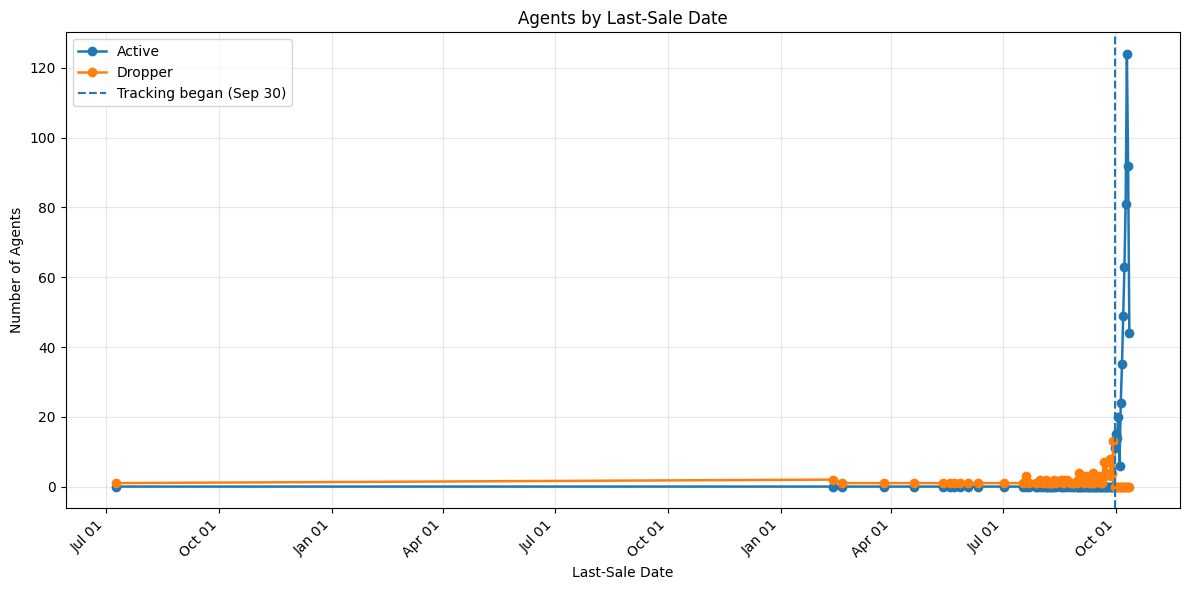

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

chk = combined.copy()

chk["last_sale_date"] = pd.to_datetime(
    chk["last_sale_date"], errors="coerce"
)

chk["group"] = np.where(
    chk["is_dropper"] == 1, "Dropper", "Active"
)

# Count agents by last-sale date and group
daily = (
    chk.dropna(subset=["last_sale_date"])
    .groupby([
        chk["last_sale_date"].dt.normalize(),
        "group"
    ])
    .size()
    .unstack(fill_value=0)
)

# Plot simple line chart
ax = daily.plot(figsize=(12, 6), marker="o", linewidth=1.8)

ax.axvline(
    pd.Timestamp("2026-09-30"),
    linestyle="--",
    label="Tracking began (Sep 30)"
)

ax.set_title("Agents by Last-Sale Date")
ax.set_xlabel("Last-Sale Date")
ax.set_ylabel("Number of Agents")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend()
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("last_sale_date_line_chart.png", dpi=200, bbox_inches="tight")
plt.show()

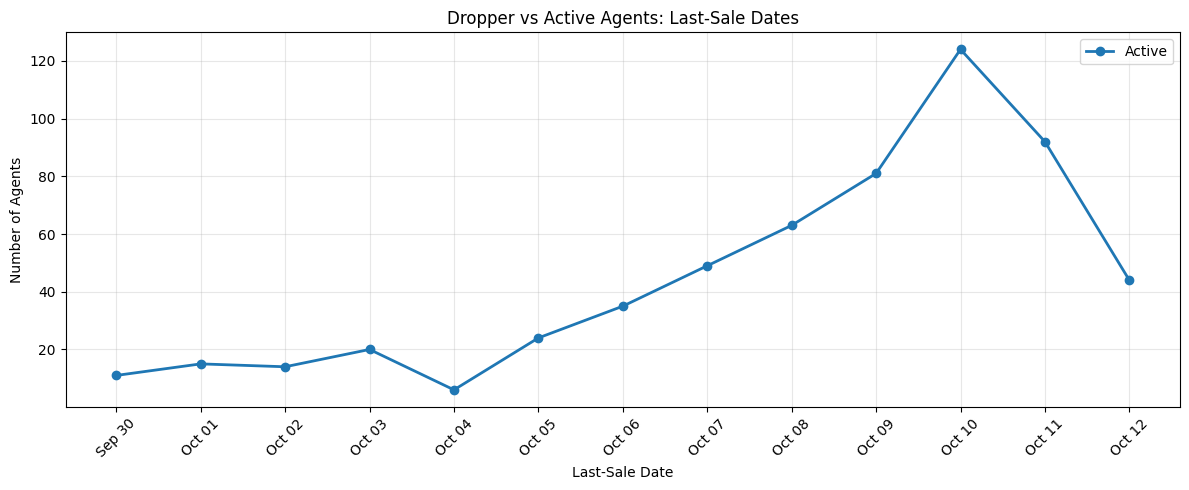

group       Active
2026-09-30      11
2026-10-01      15
2026-10-02      14
2026-10-03      20
2026-10-04       6
2026-10-05      24
2026-10-06      35
2026-10-07      49
2026-10-08      63
2026-10-09      81
2026-10-10     124
2026-10-11      92
2026-10-12      44


In [53]:

import matplotlib.dates as mdates

chk = combined.copy()

chk["last_sale_date"] = pd.to_datetime(
    chk["last_sale_date"], errors="coerce"
)

chk["group"] = np.where(
    chk["is_dropper"].eq(1), "Dropper", "Active"
)

SEP30 = pd.Timestamp("2026-09-30")
OCT12 = pd.Timestamp("2026-10-12")

# Filter to last-sale dates within the observation window
period = chk[
    chk["last_sale_date"].between(SEP30, OCT12)
].copy()

# Count agents by last-sale date and group
daily = (
    period.groupby([
        period["last_sale_date"].dt.normalize(),
        "group"
    ])
    .size()
    .unstack(fill_value=0)
)

# Include dates with zero observations
dates = pd.date_range(SEP30, OCT12, freq="D")
daily = daily.reindex(dates, fill_value=0)

# Simple line chart
fig, ax = plt.subplots(figsize=(12, 5))

for group in ["Dropper", "Active"]:
    if group in daily.columns:
        ax.plot(
            daily.index,
            daily[group],
            marker="o",
            linewidth=2,
            label=group
        )

ax.set_title("Dropper vs Active Agents: Last-Sale Dates")
ax.set_xlabel("Last-Sale Date")
ax.set_ylabel("Number of Agents")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))

plt.xticks(rotation=45)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig("last_sale_date_line_chart.png", dpi=200)
plt.show()

print(daily)

In [54]:
combined.columns

Index(['products_viewed', 'view_events', 'sales_since_sep30',
       'viewed_per_sale', 'all_sales_alltime', 'quotes_alltime', 'user_name',
       'county', 'email', 'phone_number', 'unpaid_policies', 'pwa_sales',
       'old_platform_sales', 'last_sale_date', 'is_dropper'],
      dtype='object')